# 6. Kashida

Elongation is two problems.

1. Where to elongate is a text problem.
2. What the elongation looks like is a glyph problem.

In [1]:
import numpy as np
from textsynth import Kashida, KashidaForms, Layout, Synthesizer
from textsynth.kashida import ELONGATABLE, JOINS_FORWARD, distribute
from nbutil import FONT, columns, sheet

rng = np.random.default_rng(0)
LINE = "بسم الله الرحمن الرحيم"

## Part one: where

`Kashida` finds each opening in a word where a connection can extend. Then it
shares a budget of tatweels over the openings.

In [2]:
print(Kashida(frequency=6, contrast=0.8).apply("حكيم", rng))
print(Kashida(frequency=6, contrast=0.8).apply(LINE, rng))

حـــــكـيم
بـــــسـم الله الرحـــــمـن الرحـــــيـم


`contrast` sets how `Kashida` divides the budget. `1.0` puts all of it at the
first opening. `0.0` divides it equally.

In [3]:
print(f"{'contrast':>9}  budget of 8 over 4 openings")
for value in (0.0, 0.25, 0.5, 0.8, 1.0):
    print(f"{value:>9}  {distribute(8, 4, value)}")

 contrast  budget of 8 over 4 openings
      0.0  [2, 2, 2, 2]
     0.25  [4, 2, 0, 0]
      0.5  [5, 2, 0, 0]
      0.8  [7, 1, 0, 0]
      1.0  [8, 0, 0, 0]


Two details:

- the openings overlap, so the search moves one character at a time;
- `JOINS_FORWARD` does not include lam. kashida-js does the same.

In [4]:
print("lam is not an opening:", "ل" not in JOINS_FORWARD)
print(f"{len(ELONGATABLE)} elongatable letters:", ELONGATABLE)

lam is not an opening: True
38 elongatable letters: يئهشسقفغعضصنمكظطخحجثتبپچکگݢڠڽڤیۆھڭٿٹڎډ


In [5]:
# Idempotent: it strips existing tatweels first, so running it twice does not
# accumulate them.
once = Kashida(frequency=4).apply(LINE, np.random.default_rng(1))
twice = Kashida(frequency=4).apply(once, np.random.default_rng(1))
print(once)
print(twice)
print("idempotent:", once == twice)

بــــسم الله الرحــــمن الرحــــيم
بــــسم الله الرحــــمن الرحــــيم
idempotent: True


## Part two: what it looks like

A tatweel alone is not enough. The font draws a bar next to the letter, but it
does not move the dot. `KashidaForms` makes one glyph from the bar and the
letter, and moves the dots along the extension.

The left column shows the tatweel alone. The right column shows the same text
with the patch.

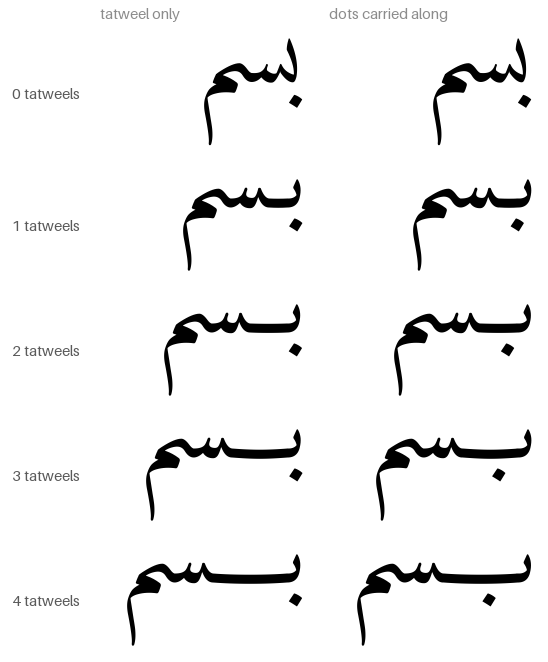

In [6]:
layout = Layout(size=100, padding=16, supersample=2)
plain = Synthesizer(font=FONT, layout=layout)
patched = Synthesizer(font=FONT, layout=layout, font_patches=[KashidaForms(letters="ب", max_run=5)])

texts = ["ب" + "ـ" * n + "سم" for n in range(5)]
columns(
    [(f"{n} tatweels", plain(t), patched(t)) for n, t in enumerate(texts)],
    headings=("tatweel only", "dots carried along"),
)

`KashidaForms` builds a form for each dotted letter, for each run length, and
for each joining context.

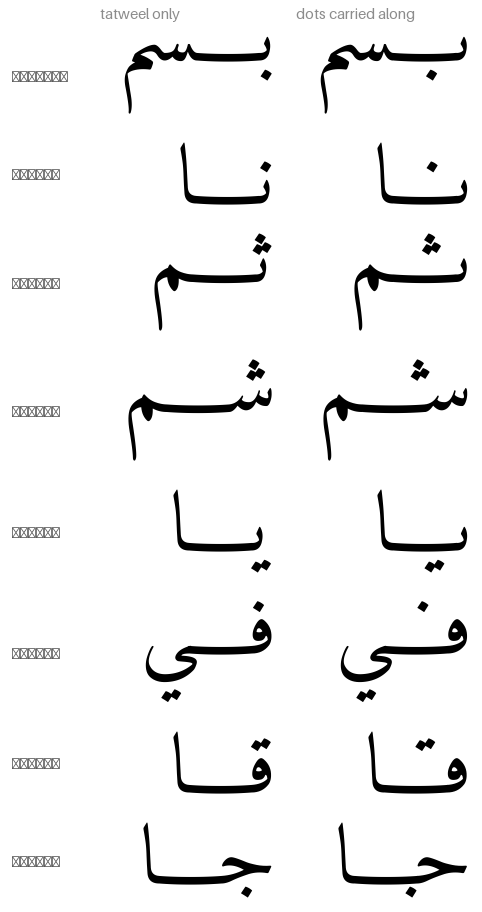

In [7]:
words = ["بــــسم", "نــــا", "ثــــم", "شــــم", "يــــا", "فــــي", "قــــا", "جــــا"]
small = Layout(size=84, padding=14, supersample=2)
p1 = Synthesizer(font=FONT, layout=small)
p2 = Synthesizer(font=FONT, layout=small, font_patches=[KashidaForms(letters="بتثنيشسجفق", max_run=5)])
columns([(w, p1(w), p2(w)) for w in words], headings=("tatweel only", "dots carried along"))

`dot_shift` sets how far the dots move along the extension. `0` keeps them
where the font put them. `0.5` puts them at the centre of the stroke.

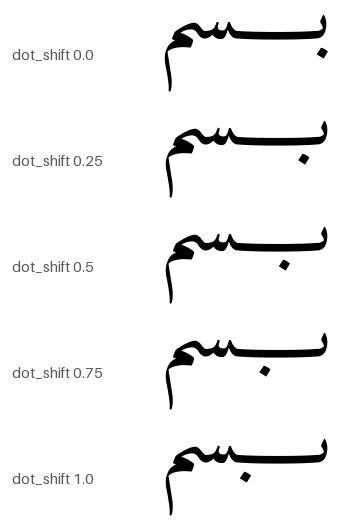

In [8]:
word = "بـــــسم"
rows = []
for value in (0.0, 0.25, 0.5, 0.75, 1.0):
    synth = Synthesizer(font=FONT, layout=small, font_patches=[KashidaForms(letters="ب", max_run=5, dot_shift=value)])
    rows.append((f"dot_shift {value}", synth(word)))
sheet(rows, gutter=150)

## Both parts together

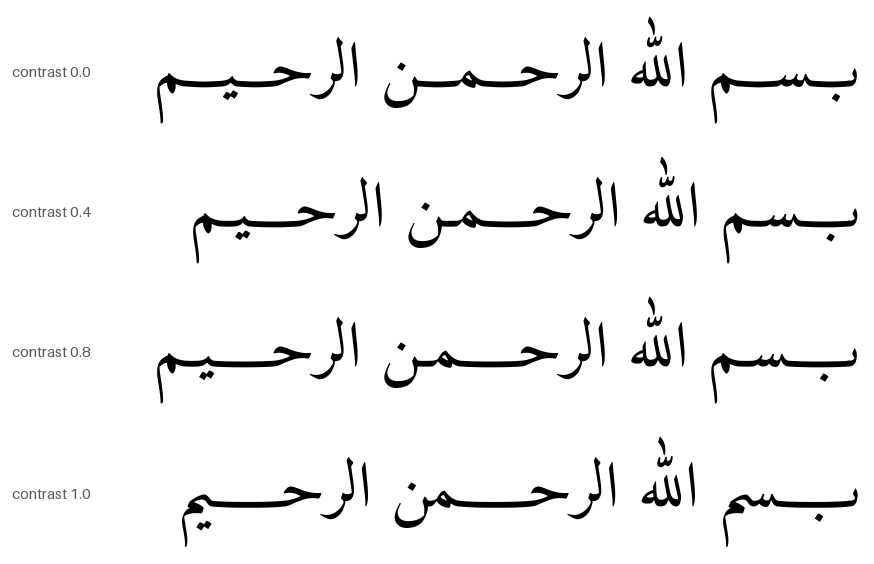

In [9]:
patch = KashidaForms(letters="بتثنيشسجفقغعصضطظكم", max_run=6)
rows = []
for value in (0.0, 0.4, 0.8, 1.0):
    synth = Synthesizer(
        font=FONT,
        layout=Layout(size=64, padding=16, supersample=2),
        text_rules=[Kashida(frequency=6, contrast=value)],
        font_patches=[patch],
    )
    rows.append((f"contrast {value}", synth(LINE)))
sheet(rows, gutter=140)

## Put `Kashida` last

`orthographic_variation` removes tatweels. A kashida before that rule does not
stay in the text.

In [10]:
from textsynth import orthographic_variation

wrong = [Kashida(frequency=6), orthographic_variation()]
right = [orthographic_variation(), Kashida(frequency=6)]
for name, rules in (("kashida first ", wrong), ("kashida last  ", right)):
    text = LINE
    r = np.random.default_rng(0)
    for rule in rules:
        text = rule.apply(text, r)
    print(name, text)

kashida first  بسم الله الرحمن الرحيم
kashida last   بـــــسـم الله الرحـــــمـن الرحـــــيـم


## The cost of the patch

`KashidaForms` builds 216 glyphs with the default values. It builds them one
time, at the first render. Decrease `letters` or `max_run` to build fewer.

In [11]:
import time

forms = KashidaForms()
synth = Synthesizer(font=FONT, text_rules=[Kashida(frequency=4)], font_patches=[forms])

start = time.perf_counter()
synth.patched_font
build = time.perf_counter() - start
start = time.perf_counter()
synth(LINE)
print(f"patch: {build * 1000:.0f} ms, {len(forms.built)} glyphs injected")
print(f"render afterwards: {(time.perf_counter() - start) * 1000:.1f} ms")

patch: 354 ms, 216 glyphs injected
render afterwards: 5.2 ms


## A font with no tatweel glyph

textsynth shapes each letter-plus-tatweel run as a probe. If the font has no
tatweel, `StretchedForm` operates. It cuts the letter's own connecting stroke
where the stroke is flat, and pulls it apart.

`stretchable()` gives `False` when there is no flat part to cut. textsynth
then does not change the letter.

In [12]:
from textsynth import Font, StretchedForm, shape

font = Font(FONT)

# Amiri has a format-3 `post` table, so most of its glyph names are invented
# by fontTools on load. Ask the shaper which glyph a letter becomes rather
# than guessing a name.
for label, text in (("medial beh", "ببب"), ("alif", "ا"), ("waw", "و"), ("seen", "سسس")):
    name = shape(text, font)[len(text) // 2].name
    form = StretchedForm(font, name, amount=0.25 * font.upem)
    print(f"{label:>10} ({name:>11})  stretchable: {form.stretchable()}")

medial beh ( glyph03999)  stretchable: True
      alif (    uni0627)  stretchable: False
       waw (    uni0648)  stretchable: True
      seen ( glyph01930)  stretchable: True
